In [1]:
import torch
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt

iris = load_iris()

# Features
y = torch.tensor(iris.data, dtype=torch.float32)

# Labels
x = torch.tensor(iris.target, dtype=torch.long)

features = torch.tensor(iris.data, dtype=torch.float32)
labels = torch.tensor(iris.target, dtype=torch.long)

# Shuffle
idx = torch.randperm(labels.size(0))
labels = labels[idx]
features = features[idx]

# Save
torch.save(features, "../../data/iris_features.pt")
torch.save(labels, "../../data/iris_labels.pt")

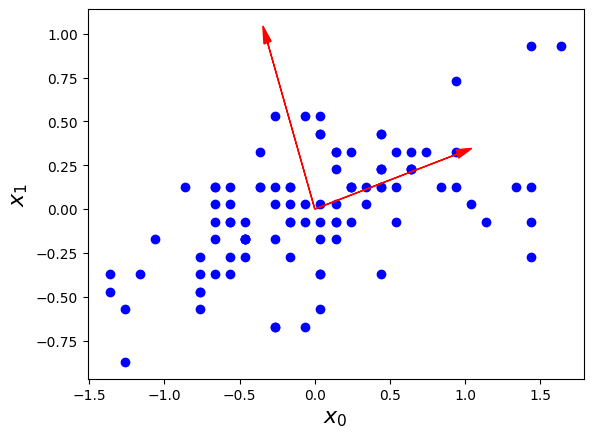

In [3]:
# Load data
x = torch.load("../../data/iris_features.pt")[:, :2]
y = torch.load("../../data/iris_labels.pt")

# Remove class 0
x = x[y != 0]

# Mean-center
x = x - x.mean(dim=0, keepdim=True)

# PCA
U, S, V = torch.pca_lowrank(x, q=2, center=False)

# Explained variance ratio
explained_variance_ratio = S**2 / torch.sum(S**2)

# Principal directions
components = V.T

# Plot
fig, ax = plt.subplots()

ax.scatter(x[:, 0], x[:, 1], color="blue")

# First principal component
ax.arrow(
    0, 0,
    components[0, 0].item(),
    components[0, 1].item(),
    head_width=0.05,
    head_length=0.1,
    fc="red",
    ec="red"
)

# Second principal component
ax.arrow(
    0, 0,
    components[1, 0].item(),
    components[1, 1].item(),
    head_width=0.05,
    head_length=0.1,
    fc="red",
    ec="red"
)

ax.set_xlabel("$x_0$", fontsize=16)
ax.set_ylabel("$x_1$", fontsize=16)

plt.show()

tensor([0.9246, 0.0531, 0.0171, 0.0052])


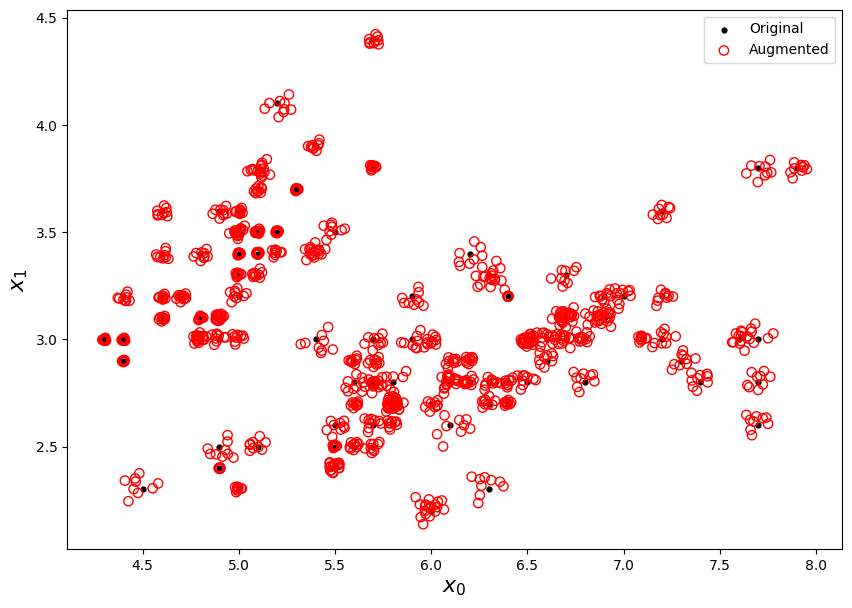

In [4]:
def fit_pca(x, n_components):
    """
    Fit PCA using PyTorch's SVD-based pca_lowrank().
    """

    # Calculate feature means
    mean = x.mean(dim=0, keepdim=True)

    # Center the data
    centered = x - mean

    # PCA
    U, S, V = torch.pca_lowrank(
        centered,
        q=n_components,
        center=False
    )

    # V: (n_features, n_components)
    # components: (n_components, n_features)
    components = V.T

    # Explained variance ratio
    explained_variance_ratio = (S ** 2) / torch.sum(S ** 2)

    return mean, components, explained_variance_ratio


def pca_transform(x, mean, components):
    """
    Transform data into PCA space.
    Equivalent to sklearn's pca.transform().
    """

    centered = x - mean

    return centered @ components.T


def pca_inverse_transform(a, mean, components):
    """
    Transform PCA representation back into original feature space.
    Equivalent to sklearn's pca.inverse_transform().
    """

    return a @ components + mean


def generate_data(mean, components, x, start):
    """
    Generate a modified version of x by perturbing
    PCA components starting at component 'start'.
    """

    # Save the original components
    original = components.clone()

    # Number of PCA components
    ncomp = components.shape[0]

    # Transform x into PCA space
    a = pca_transform(x, mean, components)

    # Modify components starting from 'start'
    for i in range(start, ncomp):
        components[i, :] += torch.normal(
            mean=0.0,
            std=0.1,
            size=(components.shape[1],),
            device=components.device
        )

    # Transform back to original feature space
    b = pca_inverse_transform(a, mean, components)

    # Restore original components
    components.copy_(original)

    return b


def main():

    # ---------------------------------------------------------
    # 1. Load tensors
    # ---------------------------------------------------------

    x = torch.load("../../data/iris_features.pt")
    y = torch.load("../../data/iris_labels.pt")

    # ---------------------------------------------------------
    # 2. Train/test split
    # ---------------------------------------------------------

    N = 120

    x_train = x[:N]
    y_train = y[:N]

    x_test = x[N:]
    y_test = y[N:]

    # ---------------------------------------------------------
    # 3. Fit PCA
    # ---------------------------------------------------------

    n_components = 4

    mean, components, explained_variance_ratio = fit_pca(
        x,
        n_components
    )

    print(explained_variance_ratio)

    # ---------------------------------------------------------
    # 4. Decide which PCA components to perturb
    # ---------------------------------------------------------

    start = 2

    # ---------------------------------------------------------
    # 5. Create space for augmented dataset
    # ---------------------------------------------------------

    nsets = 10
    nsamp = x_train.shape[0]

    newx = torch.zeros(
        (nsets * nsamp, x_train.shape[1]),
        dtype=x_train.dtype
    )

    newy = torch.zeros(
        nsets * nsamp,
        dtype=y_train.dtype
    )

    # ---------------------------------------------------------
    # 6. Generate augmented datasets
    # ---------------------------------------------------------

    for i in range(nsets):

        start_idx = i * nsamp
        end_idx = start_idx + nsamp

        if i == 0:

            # Original training data
            newx[start_idx:end_idx] = x_train
            newy[start_idx:end_idx] = y_train

        else:

            # PCA-based augmented data
            newx[start_idx:end_idx] = generate_data(
                mean,
                components,
                x_train,
                start
            )

            # Labels stay the same
            newy[start_idx:end_idx] = y_train

    plt.figure(figsize=(10, 7))

    # Original data
    plt.scatter(
        x_train[:, 0].numpy(),
        x_train[:, 1].numpy(),
        s=12,
        c="black",
        label="Original"
    )

    # Augmented data
    augmented_x = newx[nsamp:]

    plt.scatter(
        augmented_x[:, 0].numpy(),
        augmented_x[:, 1].numpy(),
        s=45,
        facecolors="none",
        edgecolors="red",
        label="Augmented"
    )

    plt.xlabel("$x_0$", fontsize=16)
    plt.ylabel("$x_1$", fontsize=16)

    plt.legend()
    plt.show()

    # ---------------------------------------------------------
    # 7. Shuffle augmented dataset
    # ---------------------------------------------------------

    idx = torch.randperm(nsets * nsamp)

    newx = newx[idx]
    newy = newy[idx]

    # ---------------------------------------------------------
    # 8. Save datasets
    # ---------------------------------------------------------

    torch.save(
        newx,
        "../../data/augmented/iris_train_features_augmented.pt"
    )

    torch.save(
        newy,
        "../../data/augmented/iris_train_labels_augmented.pt"
    )

    # Test set is NOT augmented
    torch.save(
        x_test,
        "../../data/augmented/iris_test_features_augmented.pt"
    )

    torch.save(
        y_test,
        "../../data/augmented/iris_test_labels_augmented.pt"
    )


if __name__ == "__main__":
    main()